This code is authored by Nivetha

# Bipartite network comparison (fast version)

Compares the real **recipe-ingredient** network with five random models (ER, WS, BA, HK, DP).
Everything runs `N_RUNS` times per model and every metric is reported as **mean +/- SD over the runs**.

Speed comes from working on a dense 0/1 biadjacency matrix `A` (recipes x ingredients) with BLAS matrix
products instead of Python loops over node pairs. All metrics are exact (same definitions as the
original networkx code), nothing is sampled or approximated.

In [ ]:
import os, time, random
from math import comb

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

try:
    from IPython.display import display
except ImportError:         
    display = print

DATA_DIR   = os.environ.get("/Users/nivetha/Desktop/Classes/ComplexNetworks/CourseProject/Nivetha_Codes_Graphs/Plots_Graphs")
NODES_FILE = "nodes_9.0.csv"
EDGES_FILE = "edges_6.0.csv"

N_RUNS     = 20 #relealisations
BASE_SEED  = 42          
OUTPUT_DIR = "bipartite_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODELS = ["ER", "WS", "BA", "HK", "DP"]
MODEL_ORDER = ["Original"] + MODELS
STYLE = {
    "Original": dict(color="black",      marker="o", lw=2.2, ms=5),
    "ER":       dict(color="tab:gray",   marker="s", lw=1.5, ms=4),
    "WS":       dict(color="tab:green",  marker="^", lw=1.5, ms=4),
    "BA":       dict(color="tab:red",    marker="D", lw=1.5, ms=4),
    "HK":       dict(color="tab:purple", marker="v", lw=1.5, ms=4),
    "DP":       dict(color="tab:blue",   marker="P", lw=1.5, ms=4),
}

In [ ]:
nodes = pd.read_csv(os.path.join(DATA_DIR, NODES_FILE))
edges = pd.read_csv(os.path.join(DATA_DIR, EDGES_FILE))

node_type = nodes["Type"].str.lower()
recipe_nodes     = nodes.loc[node_type == "recipe", "Id"].tolist()
ingredient_nodes = nodes.loc[node_type == "ingredient", "Id"].tolist()
nU, nV = len(recipe_nodes), len(ingredient_nodes)

r_index = {x: i for i, x in enumerate(recipe_nodes)}
i_index = {x: j for j, x in enumerate(ingredient_nodes)}

s_r, s_i = edges["Source"].map(r_index), edges["Source"].map(i_index)
t_r, t_i = edges["Target"].map(r_index), edges["Target"].map(i_index)
fwd = (s_r.notna() & t_i.notna()).to_numpy()      # Source = recipe,     Target = ingredient
rev = (s_i.notna() & t_r.notna()).to_numpy()      # Source = ingredient, Target = recipe
valid = fwd | rev
if (~valid).any():
    print(f"WARNING: ignoring {(~valid).sum()} edges that are not recipe-ingredient edges")

rows_all = np.where(fwd, s_r.to_numpy(), t_r.to_numpy())[valid].astype(np.int64)
cols_all = np.where(fwd, t_i.to_numpy(), s_i.to_numpy())[valid].astype(np.int64)
codes0 = np.unique(rows_all * nV + cols_all)       
rows0, cols0 = codes0 // nV, codes0 % nV   
m = len(codes0)

print(f"Recipes: {nU}")
print(f"Ingredients: {nV}")
print(f"Edges: {m}")

def to_dense(rows, cols):
    A = np.zeros((nU, nV), dtype=np.float32)
    A[rows, cols] = 1.0
    return A

Recipes: 3933
Ingredients: 568
Edges: 46669


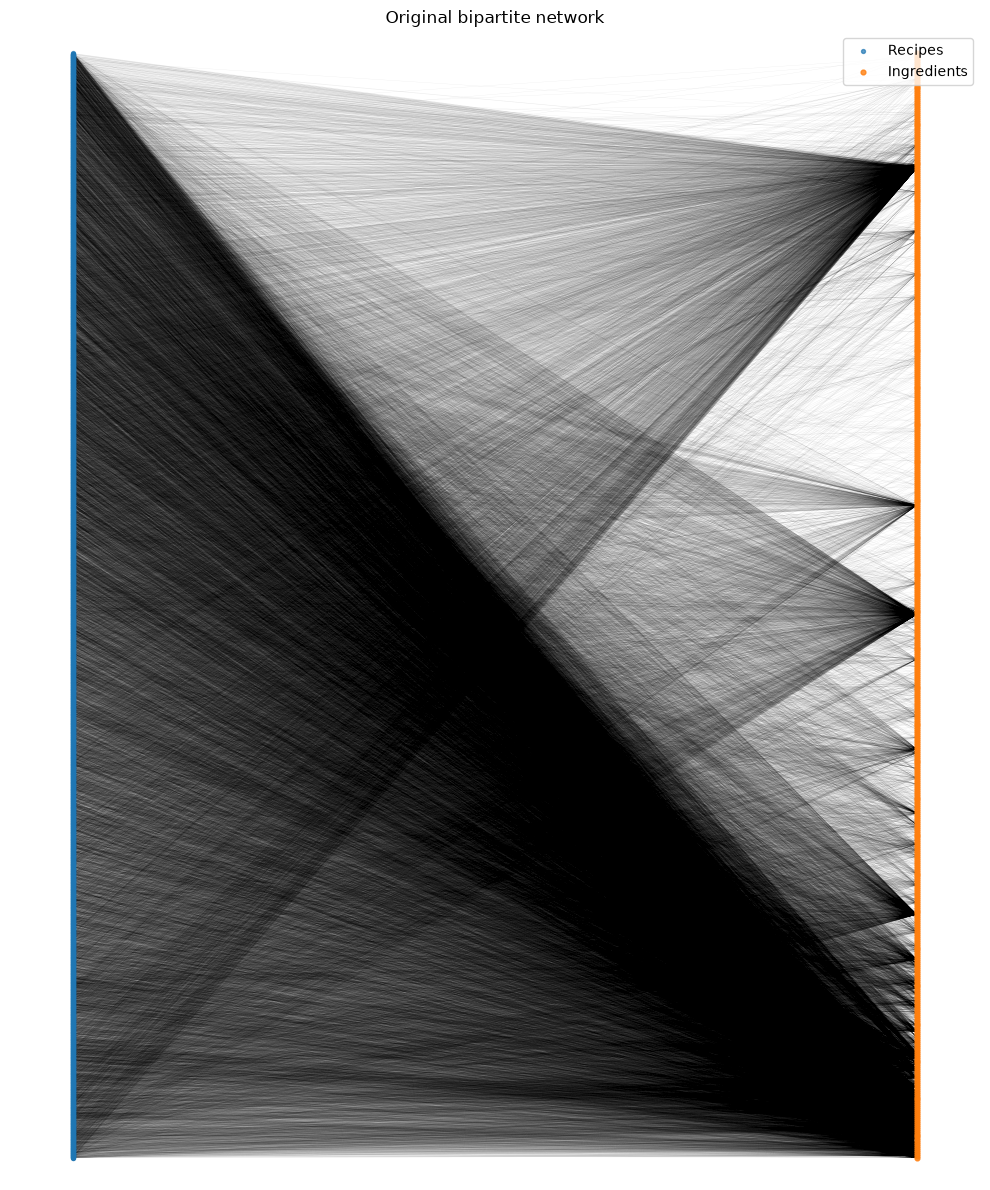

In [ ]:
# the original bipartite network
yU, yV, X_R = np.linspace(0, 1, nU), np.linspace(0, 1, nV), 1.33
segs = np.stack([np.column_stack([np.zeros(m), yU[rows0]]),
                 np.column_stack([np.full(m, X_R), yV[cols0]])], axis=1)
fig, ax = plt.subplots(figsize=(10, 12))
ax.add_collection(LineCollection(segs, colors="k", linewidths=0.2, alpha=0.08))
ax.scatter(np.zeros(nU), yU, s=8, c="tab:blue", alpha=0.7, label="Recipes", zorder=3)
ax.scatter(np.full(nV, X_R), yV, s=12, c="tab:orange", alpha=0.8, label="Ingredients", zorder=3)
ax.set_xlim(-0.1, X_R + 0.1); ax.set_ylim(-0.02, 1.02)
ax.set_title("Original bipartite network"); ax.legend(loc="upper right"); ax.axis("off")
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "original_network.png"), dpi=150); plt.show()

# Network Models

In [ ]:
def gen_er(seed):
    codes = np.random.default_rng(seed).choice(nU * nV, size=m, replace=False)
    return codes // nV, codes % nV


def gen_ws(seed, beta=0.1):
    rng = random.Random(seed)
    k, remainder = divmod(m, nU)
    assert k + 1 <= nV, "ring block larger than the number of ingredients"
    counts = np.full(nU, k); counts[:remainder] += 1                 
    rows = np.repeat(np.arange(nU), counts)
    offs = np.arange(m) - np.repeat(np.cumsum(counts) - counts, counts)
    starts = (np.arange(nU) * max(k, 1)) % nV
    cols = ((np.repeat(starts, counts) + offs) % nV).tolist()
    rows = rows.tolist()

    nbrs = [set() for _ in range(nU)] # current neighbours per recipe
    for r, c in zip(rows, cols):
        nbrs[r].add(c)
    rand, randrange = rng.random, rng.randrange
    for idx in range(m):
        if rand() >= beta:
            continue
        s = nbrs[rows[idx]]
        s.discard(cols[idx]) # removing old edge
        new = randrange(nV)
        while new in s:   # new target 
            new = randrange(nV)
        s.add(new)
        cols[idx] = new
    return np.array(rows), np.array(cols)


def _grow(seed, p_close, alpha=1.0):
    
    rng = random.Random(seed)
    rand, randrange = rng.random, rng.randrange
    er_, ec_ = [0] * m, [0] * m             
    present = set()                          
    track = p_close > 0
    if track:
        nbU = [[] for _ in range(nU)]      
        nbV = [[] for _ in range(nV)]  
        active = []                     
    E = 0
    aU, aV = alpha * nU, alpha * nV

    def add(u, v):
        nonlocal E
        er_[E] = u; ec_[E] = v; E += 1
        present.add(u * nV + v)
        if track:
            if not nbU[u]:
                active.append(u)
            nbU[u].append(v); nbV[v].append(u)

    while E < m:
        if track and rand() < p_close and active:
            u = active[randrange(len(active))]
            lst = nbU[u]
            v = lst[randrange(len(lst))]
            lv = nbV[v]
            if len(lv) > 1:                               
                r2 = lv[randrange(len(lv))]
                while r2 == u:
                    r2 = lv[randrange(len(lv))]
                options = [i for i in nbU[r2] if (u * nV + i) not in present]
                if options:
                    add(u, options[randrange(len(options))])
                    continue
        for _ in range(1000):                               
            u = er_[randrange(E)] if rand() * (E + aU) < E else randrange(nU)
            v = ec_[randrange(E)] if rand() * (E + aV) < E else randrange(nV)
            if (u * nV + v) not in present:
                add(u, v)
                break
        else:
            raise RuntimeError("Could not add a new unique edge.")
    return np.array(er_), np.array(ec_)


def gen_ba(seed, alpha=1.0):
    return _grow(seed, p_close=0.0, alpha=alpha)

def gen_hk(seed, p_close=0.3, alpha=1.0):
    return _grow(seed, p_close=p_close, alpha=alpha)


def gen_dp(seed, swaps_per_edge=10):
    rng = random.Random(seed)
    rnd = rng.random
    rows, cols = rows0.tolist(), cols0.tolist()
    present = {r * nV + c for r, c in zip(rows, cols)}
    E = len(rows)
    target, done, attempts = swaps_per_edge * E, 0, 0
    max_attempts = 100 * target
    Em1 = E - 1
    while done < target and attempts < max_attempts:
        attempts += 1
        i = int(rnd() * E)
        j = int(rnd() * Em1)
        if j >= i:
            j += 1                                          
        r1, g1, r2, g2 = rows[i], cols[i], rows[j], cols[j]
        if r1 == r2 or g1 == g2:
            continue
        a, b = r1 * nV + g2, r2 * nV + g1
        if a in present or b in present:
            continue
        present.remove(r1 * nV + g1); present.remove(r2 * nV + g2)
        present.add(a); present.add(b)
        cols[i], cols[j] = g2, g1
        done += 1
    if done < target:
        print(f"WARNING: DP performed only {done}/{target} swaps")
    return rows0.copy(), np.array(cols)


GENERATORS = {"ER": gen_er, "WS": gen_ws, "BA": gen_ba, "HK": gen_hk, "DP": gen_dp}

In [6]:
t_start = time.perf_counter()
generated = {name: [] for name in MODELS}          # name -> list of (rows, cols) edge arrays
deg_rec0, deg_ing0 = np.bincount(rows0, minlength=nU), np.bincount(cols0, minlength=nV)

for name, build in GENERATORS.items():
    t = time.perf_counter()
    for run in range(N_RUNS):
        rows, cols = build(BASE_SEED + run)
        assert len(rows) == m and len(np.unique(rows * nV + cols)) == m, f"{name}: wrong edge count"
        if name == "DP":                           # degree-preserving: every node keeps its exact degree
            assert np.array_equal(np.bincount(rows, minlength=nU), deg_rec0)
            assert np.array_equal(np.bincount(cols, minlength=nV), deg_ing0)
        generated[name].append((rows.astype(np.int32), cols.astype(np.int32)))
    print(f"{name}: built {N_RUNS} networks in {time.perf_counter() - t:.1f}s")
print("DP: all networks match the original degree sequence")
print(f"Total generation time: {time.perf_counter() - t_start:.1f}s")

ER: built 20 networks in 0.1s
WS: built 20 networks in 0.2s
BA: built 20 networks in 0.4s
HK: built 20 networks in 0.7s
DP: built 20 networks in 5.1s
DP: all networks match the original degree sequence
Total generation time: 6.5s


In [ ]:
CLUSTER_CHUNK = 1024  # rows of S processed at a time 

def side_stats(M, chunk=CLUSTER_CHUNK):
   
    n, p = M.shape
    deg = M.sum(axis=1, dtype=np.float64)
    MT = np.ascontiguousarray(M.T)
    clustering = np.zeros(n)
    hist = np.zeros(p + 1, dtype=np.int64)
    for r0 in range(0, n, chunk):
        r1 = min(n, r0 + chunk)
        S = M[r0:r1] @ MT                                  
        ar = np.arange(r1 - r0)
        S[ar, r0 + ar] = 0.0                              
        mask = S > 0
        cnt = mask.sum(axis=1)
        Sd = S.astype(np.float64)
        union = deg[r0:r1, None] + deg[None, :] - Sd  # |N(u) U N(v)|
        J = np.divide(Sd, union, out=np.zeros_like(Sd), where=mask)   # Jaccard, only where they share
        clustering[r0:r1] = np.divide(J.sum(axis=1), cnt, out=np.zeros(r1 - r0), where=cnt > 0)
        hist += np.bincount(S.astype(np.int64).ravel(), minlength=p + 1)
    hist[0] = 0
    assert (hist % 2 == 0).all()
    pairs = hist // 2                                       
    w = np.arange(p + 1, dtype=np.int64)
    return dict(clustering=clustering,
                pairs=pairs,
                c4=int((pairs * (w * (w - 1) // 2)).sum()),
                total_shared=int((pairs * w).sum()),
                pairs_sharing=int(pairs.sum()))


def bfs_distance_sums(X):
    nr, ni = X.shape
    XT = np.ascontiguousarray(X.T)
    visR = np.eye(nr, dtype=bool)              
    visI = X > 0                                
    count = int(visI.sum()); total = count
    maxd = 1 if count else 0
    frontier, at_ingredients, d = X, True, 1
    while True:
        d += 1
        if at_ingredients:
            new = (frontier @ XT) > 0; new &= ~visR; visR |= new
        else:
            new = (frontier @ X) > 0;  new &= ~visI; visI |= new
        c = int(new.sum())
        if c == 0:
            break
        total += d * c; count += c; maxd = d
        frontier = new.astype(np.float32)
        at_ingredients = not at_ingredients
    return total, count, maxd


def connectivity_metrics(rows, cols, A):
    N = nU + nV
    adj = csr_matrix((np.ones(len(rows)), (rows, cols + nU)), shape=(N, N))
    n_comp, labels = connected_components(adj, directed=False)
    sizes = np.bincount(labels)
    g = int(np.argmax(sizes))
    rec_in, ing_in = labels[:nU] == g, labels[nU:] == g
    X = A if (rec_in.all() and ing_in.all()) else np.ascontiguousarray(A[np.ix_(rec_in, ing_in)])
    t1, c1, d1 = bfs_distance_sums(X)                        # sources = recipes
    t2, c2, d2 = bfs_distance_sums(np.ascontiguousarray(X.T))  # sources = ingredients
    return {
        "Connected components": int(n_comp),
        "Giant component size": int(sizes[g]),
        "Giant component fraction": float(sizes[g] / N),
        "Isolated nodes": int((sizes == 1).sum()),
        "Average shortest path (giant)": (t1 + t2) / (c1 + c2) if (c1 + c2) else float("nan"),
        "Diameter (giant)": float(max(d1, d2)),
    }


PAIRS_REC, PAIRS_ING = comb(nU, 2), comb(nV, 2)
POSSIBLE_C4 = PAIRS_REC * PAIRS_ING

def shared_pmf(pairs, total_pairs):
    p = pairs.astype(np.float64)
    p[0] = total_pairs - pairs.sum()
    return np.trim_zeros(p / total_pairs, "b")


def analyse(rows, cols):
    A = to_dense(rows, cols)
    deg_rec, deg_ing = np.bincount(rows, minlength=nU), np.bincount(cols, minlength=nV)
    rec = side_stats(A)
    ing = side_stats(np.ascontiguousarray(A.T))

    assert rec["c4"] == ing["c4"], "4-cycle count differs between recipe and ingredient side"
    assert rec["total_shared"] == int((deg_ing * (deg_ing - 1) // 2).sum())
    assert ing["total_shared"] == int((deg_rec * (deg_rec - 1) // 2).sum())

    scalars = {
        "Recipe avg degree": float(deg_rec.mean()),
        "Ingredient avg degree": float(deg_ing.mean()),
        "Recipes avg clustering": float(rec["clustering"].mean()),
        "Ingredients avg clustering": float(ing["clustering"].mean()),
        "Bipartite clustering coefficient": float((rec["clustering"].sum() + ing["clustering"].sum()) / (nU + nV)),
        **connectivity_metrics(rows, cols, A),
        "Four-cycle count": rec["c4"],
        "Four-cycle density": rec["c4"] / POSSIBLE_C4,
        "Mean shared ingredients per recipe pair": rec["total_shared"] / PAIRS_REC,
        "Mean shared recipes per ingredient pair": ing["total_shared"] / PAIRS_ING,
        "Fraction of recipe pairs sharing an ingredient": rec["pairs_sharing"] / PAIRS_REC,
        "Fraction of ingredient pairs sharing a recipe": ing["pairs_sharing"] / PAIRS_ING,
    }
    arrays = dict(deg_rec=deg_rec, deg_ing=deg_ing,
                  pmf_rec=shared_pmf(rec["pairs"], PAIRS_REC),
                  pmf_ing=shared_pmf(ing["pairs"], PAIRS_ING))
    return scalars, arrays

In [8]:
t_start = time.perf_counter()
records, arrays = [], {}

sc, ar = analyse(rows0, cols0)
records.append({"model": "Original", "run": 0, **sc})
arrays["Original"] = [ar]
print(f"Original analysed in {time.perf_counter() - t_start:.1f}s")

for name in MODELS:
    t = time.perf_counter()
    arrays[name] = []
    for run, (rows, cols) in enumerate(generated[name]):
        sc, ar = analyse(rows, cols)
        records.append({"model": name, "run": run, **sc})
        arrays[name].append(ar)
    print(f"{name}: {N_RUNS} networks analysed in {time.perf_counter() - t:.1f}s")
print(f"Total analysis time: {time.perf_counter() - t_start:.1f}s")

runs_df = pd.DataFrame(records)
METRICS = [c for c in runs_df.columns if c not in ("model", "run")]

Original analysed in 0.2s
ER: 20 networks analysed in 4.1s
WS: 20 networks analysed in 3.7s
BA: 20 networks analysed in 4.2s
HK: 20 networks analysed in 4.0s
DP: 20 networks analysed in 3.2s
Total analysis time: 19.5s


## Mmean and standard deviation 

In [ ]:
grp = runs_df.groupby("model")[METRICS]
means = grp.mean().T.loc[:, MODEL_ORDER] # exact means
sds   = grp.std(ddof=1).fillna(0.0).T.loc[:, MODEL_ORDER]     

def fmt(x):
    if x == 0:               return "0"
    if abs(x) >= 1e4:        return f"{x:,.1f}"
    if abs(x) < 1e-3:        return f"{x:.3e}"
    return f"{x:.4f}"

summary = pd.DataFrame({mdl: [f"{fmt(means.loc[k, mdl])} \u00b1 {fmt(sds.loc[k, mdl])}" for k in METRICS]
                        for mdl in MODEL_ORDER}, index=METRICS)

print(f"Mean \u00b1 SD over {N_RUNS} runs per model (Original = the single real network)\n")
display(summary)

runs_df.to_csv(os.path.join(OUTPUT_DIR, "all_runs.csv"), index=False)
means.to_csv(os.path.join(OUTPUT_DIR, "metric_means.csv"))
sds.to_csv(os.path.join(OUTPUT_DIR, "metric_sds.csv"))
summary.to_csv(os.path.join(OUTPUT_DIR, "metric_summary_mean_pm_sd.csv"))

Mean ± SD over 20 runs per model (Original = the single real network)



,Original,ER,WS,BA,HK,DP
Recipe avg degree,11.8660 ± 0,11.8660 ± 0,11.8660 ± 0,11.8660 ± 0,11.8660 ± 0,11.8660 ± 0
Ingredient avg degree,82.1637 ± 0,82.1637 ± 0,82.1637 ± 0,82.1637 ± 0,82.1637 ± 0,82.1637 ± 0
Recipes avg clustering,0.1686 ± 0,0.0495 ± 1.424e-05,0.1747 ± 0.0014,0.0511 ± 6.025e-04,0.0460 ± 6.164e-04,0.1572 ± 1.356e-04
Ingredients avg clustering,0.0205 ± 0,0.0129 ± 1.794e-05,0.0440 ± 4.836e-04,0.0195 ± 2.512e-04,0.0172 ± 1.998e-04,0.0126 ± 5.188e-04
Bipartite clustering coefficient,0.1499 ± 0,0.0449 ± 1.374e-05,0.1582 ± 0.0013,0.0471 ± 5.120e-04,0.0423 ± 5.261e-04,0.1390 ± 1.512e-04
Connected components,1.0000 ± 0,1.0500 ± 0.2236,1.0000 ± 0,292.2500 ± 13.6647,562.7500 ± 21.5452,1.0000 ± 0
Giant component size,4501.0000 ± 0,4500.9500 ± 0.2236,4501.0000 ± 0,4209.6500 ± 13.6624,3939.0000 ± 21.5822,4501.0000 ± 0
Giant component fraction,1.0000 ± 0,1.0000 ± 4.968e-05,1.0000 ± 0,0.9353 ± 0.0030,0.8751 ± 0.0048,1.0000 ± 0
Isolated nodes,0 ± 0,0.0500 ± 0.2236,0 ± 0,291.1500 ± 13.6739,561.5000 ± 21.5223,0 ± 0
Average shortest path (giant),2.4506 ± 0,3.4087 ± 3.334e-04,3.6701 ± 0.0021,3.2704 ± 0.0121,3.1156 ± 0.0131,2.2914 ± 0.0012


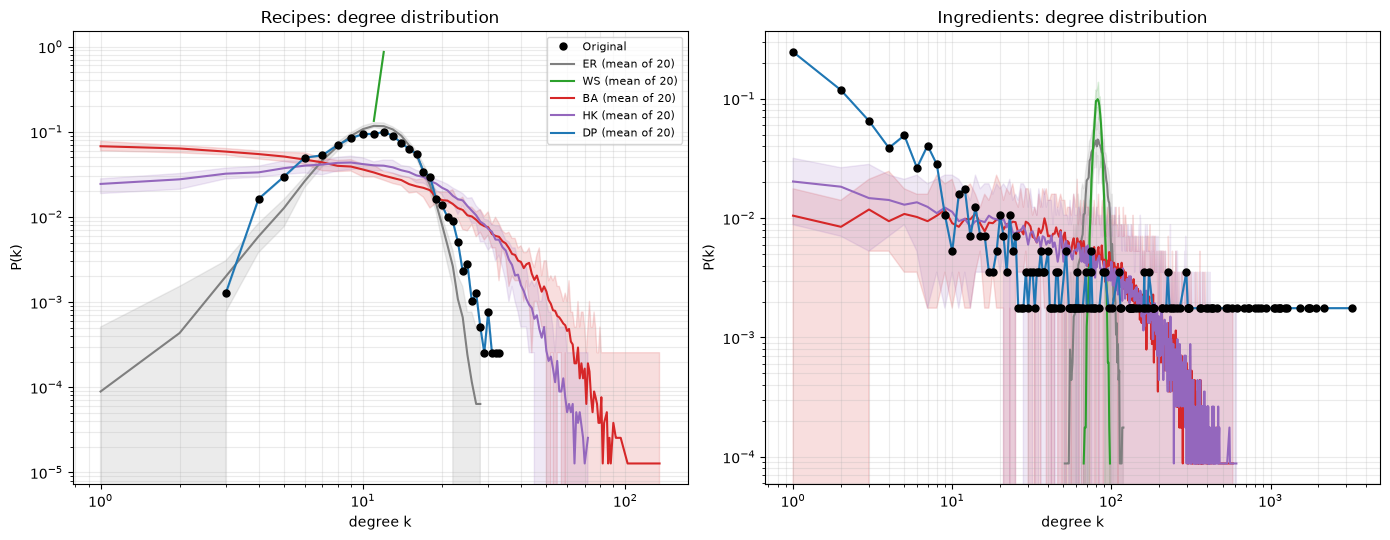

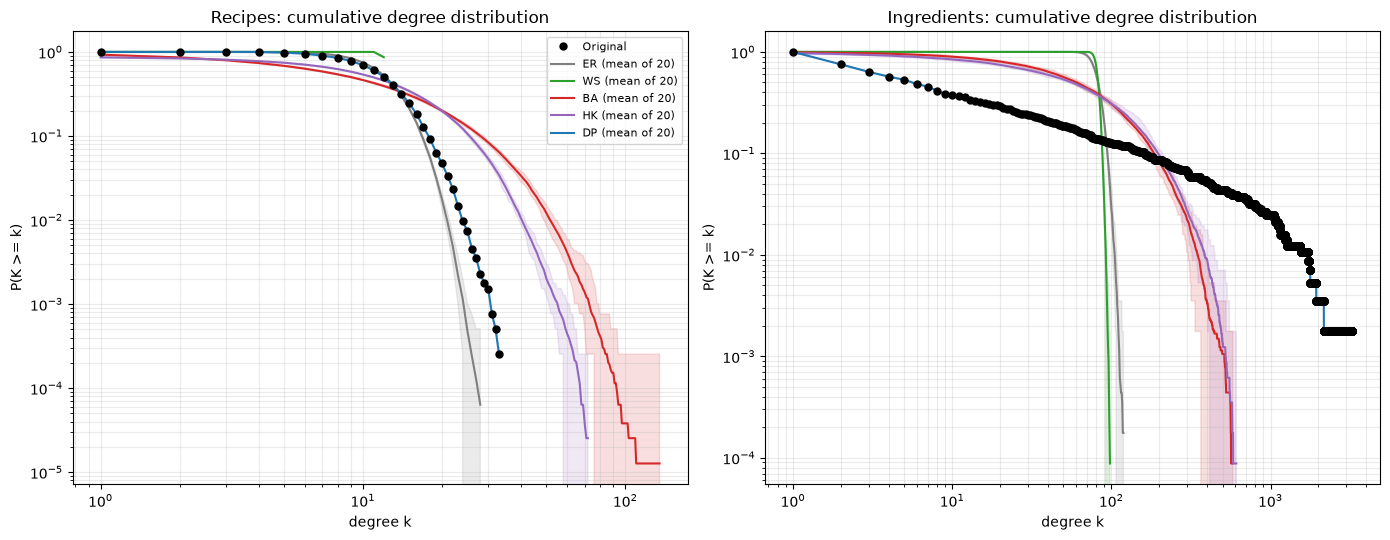

In [ ]:
def pmf_band(deg_list):
    K = max(int(d.max()) for d in deg_list)
    Y = np.array([np.bincount(d, minlength=K + 1)[1:] / len(d) for d in deg_list])
    keep = Y.max(axis=0) > 0
    return np.arange(1, K + 1)[keep], Y[:, keep].mean(0), Y[:, keep].min(0), Y[:, keep].max(0)

def cdf_band(deg_list):
    K = max(int(d.max()) for d in deg_list)

    Y = np.array([
        np.cumsum(np.bincount(d, minlength=K + 1)[::-1])[::-1][1:K + 1] / len(d)
        for d in deg_list
    ])

    return np.arange(1, K + 1), Y.mean(0), Y.min(0), Y.max(0)

def band_plot(ax, band_fn, key, ylabel, title):
    for name in MODEL_ORDER:
        x, mean, lo, hi = band_fn([a[key] for a in arrays[name]])
        st = STYLE[name]
        if name == "Original":
            ax.plot(x, mean, color=st["color"], marker=st["marker"], ms=st["ms"], lw=0, label=name, zorder=5)
        else:
            ax.plot(x, mean, color=st["color"], lw=st["lw"], label=f"{name} (mean of {N_RUNS})")
            ax.fill_between(x, lo, hi, color=st["color"], alpha=0.15)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("degree k"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(True, which="both", alpha=0.25)

for fn_name, band_fn, ylab, fname in [("Degree distribution", pmf_band, "P(k)", "degree_distribution.png"),
                                      ("Cumulative degree distribution", cdf_band, "P(K >= k)", "degree_cdf.png")]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    band_plot(axes[0], band_fn, "deg_rec", ylab, f"Recipes: {fn_name.lower()}")
    band_plot(axes[1], band_fn, "deg_ing", ylab, f"Ingredients: {fn_name.lower()}")
    axes[0].legend(fontsize=8)
    fig.tight_layout(); 
    fig.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150); plt.show()

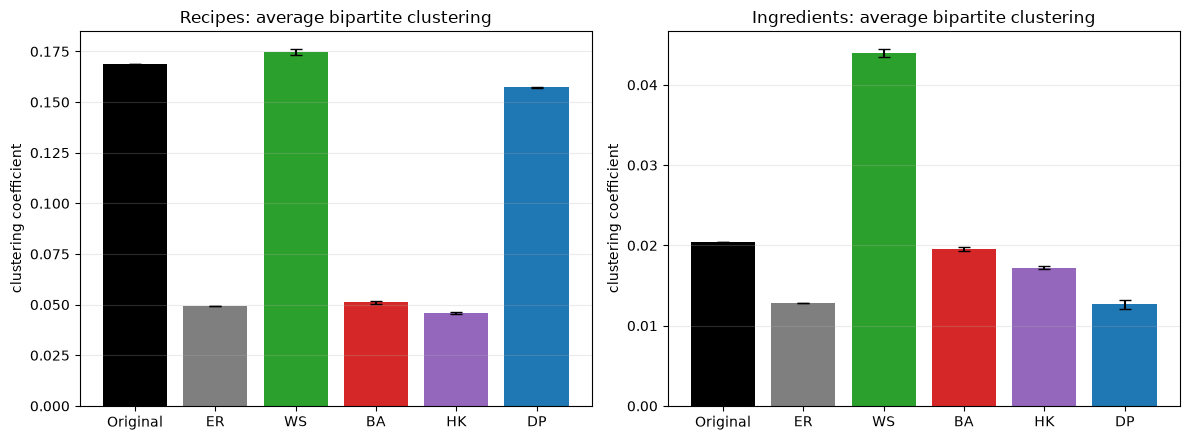

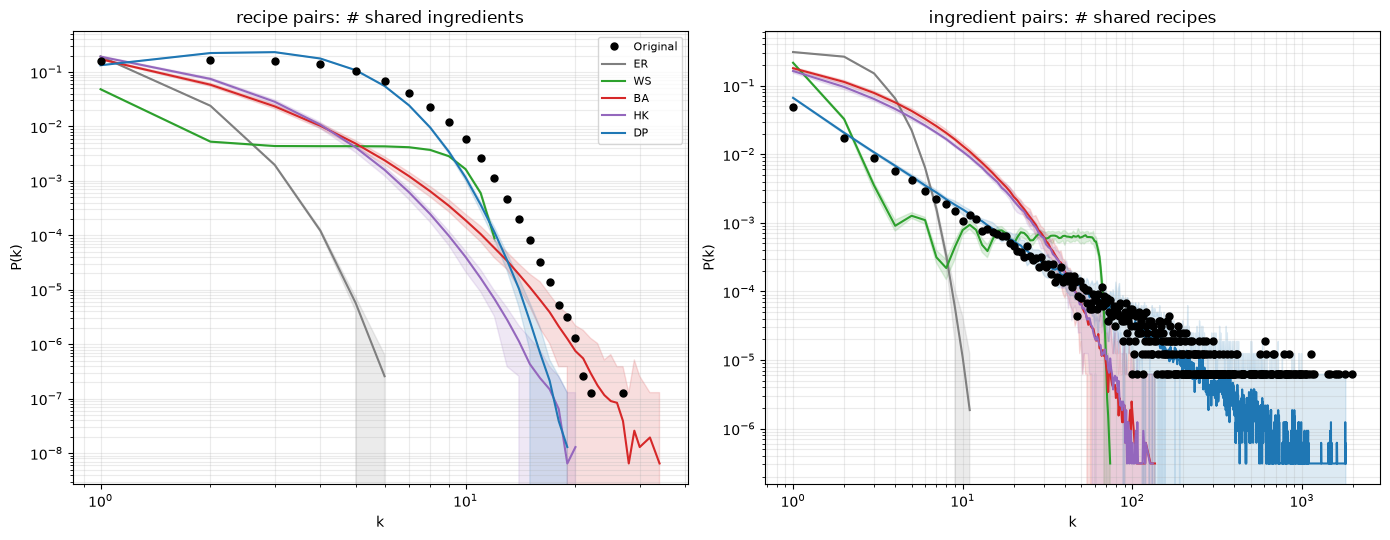

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, key, title in zip(axes, ["Recipes avg clustering", "Ingredients avg clustering"],
                          ["Recipes", "Ingredients"]):
    ax.bar(MODEL_ORDER, means.loc[key, MODEL_ORDER], yerr=sds.loc[key, MODEL_ORDER], capsize=4,
           color=[STYLE[mdl]["color"] for mdl in MODEL_ORDER])
    ax.set_title(f"{title}: average bipartite clustering"); ax.set_ylabel("clustering coefficient")
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "clustering.png"), dpi=150); plt.show()

# distribution of shared neighbours per node pair
def pad_stack(pmfs):
    L = max(len(p) for p in pmfs)
    return np.array([np.pad(p, (0, L - len(p))) for p in pmfs])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, key, title in zip(axes, ["pmf_rec", "pmf_ing"],
                          ["recipe pairs: # shared ingredients", "ingredient pairs: # shared recipes"]):
    for name in MODEL_ORDER:
        Y = pad_stack([a[key] for a in arrays[name]])[:, 1:]          # k >= 1
        x = np.arange(1, Y.shape[1] + 1); keep = Y.max(0) > 0; st = STYLE[name]
        if name == "Original":
            ax.plot(x[keep], Y.mean(0)[keep], color=st["color"], marker=st["marker"], ms=st["ms"], lw=0,
                    label=name, zorder=5)
        else:
            ax.plot(x[keep], Y.mean(0)[keep], color=st["color"], lw=st["lw"], label=name)
            ax.fill_between(x[keep], Y.min(0)[keep], Y.max(0)[keep], color=st["color"], alpha=0.15)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("k"); ax.set_ylabel("P(k)")
    ax.set_title(title); ax.grid(True, which="both", alpha=0.25)
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "shared_neighbours.png"), dpi=150); plt.show()

# Four cycle counts


Showing 152 nodes, 685 edges, 682 butterfly edges (original)


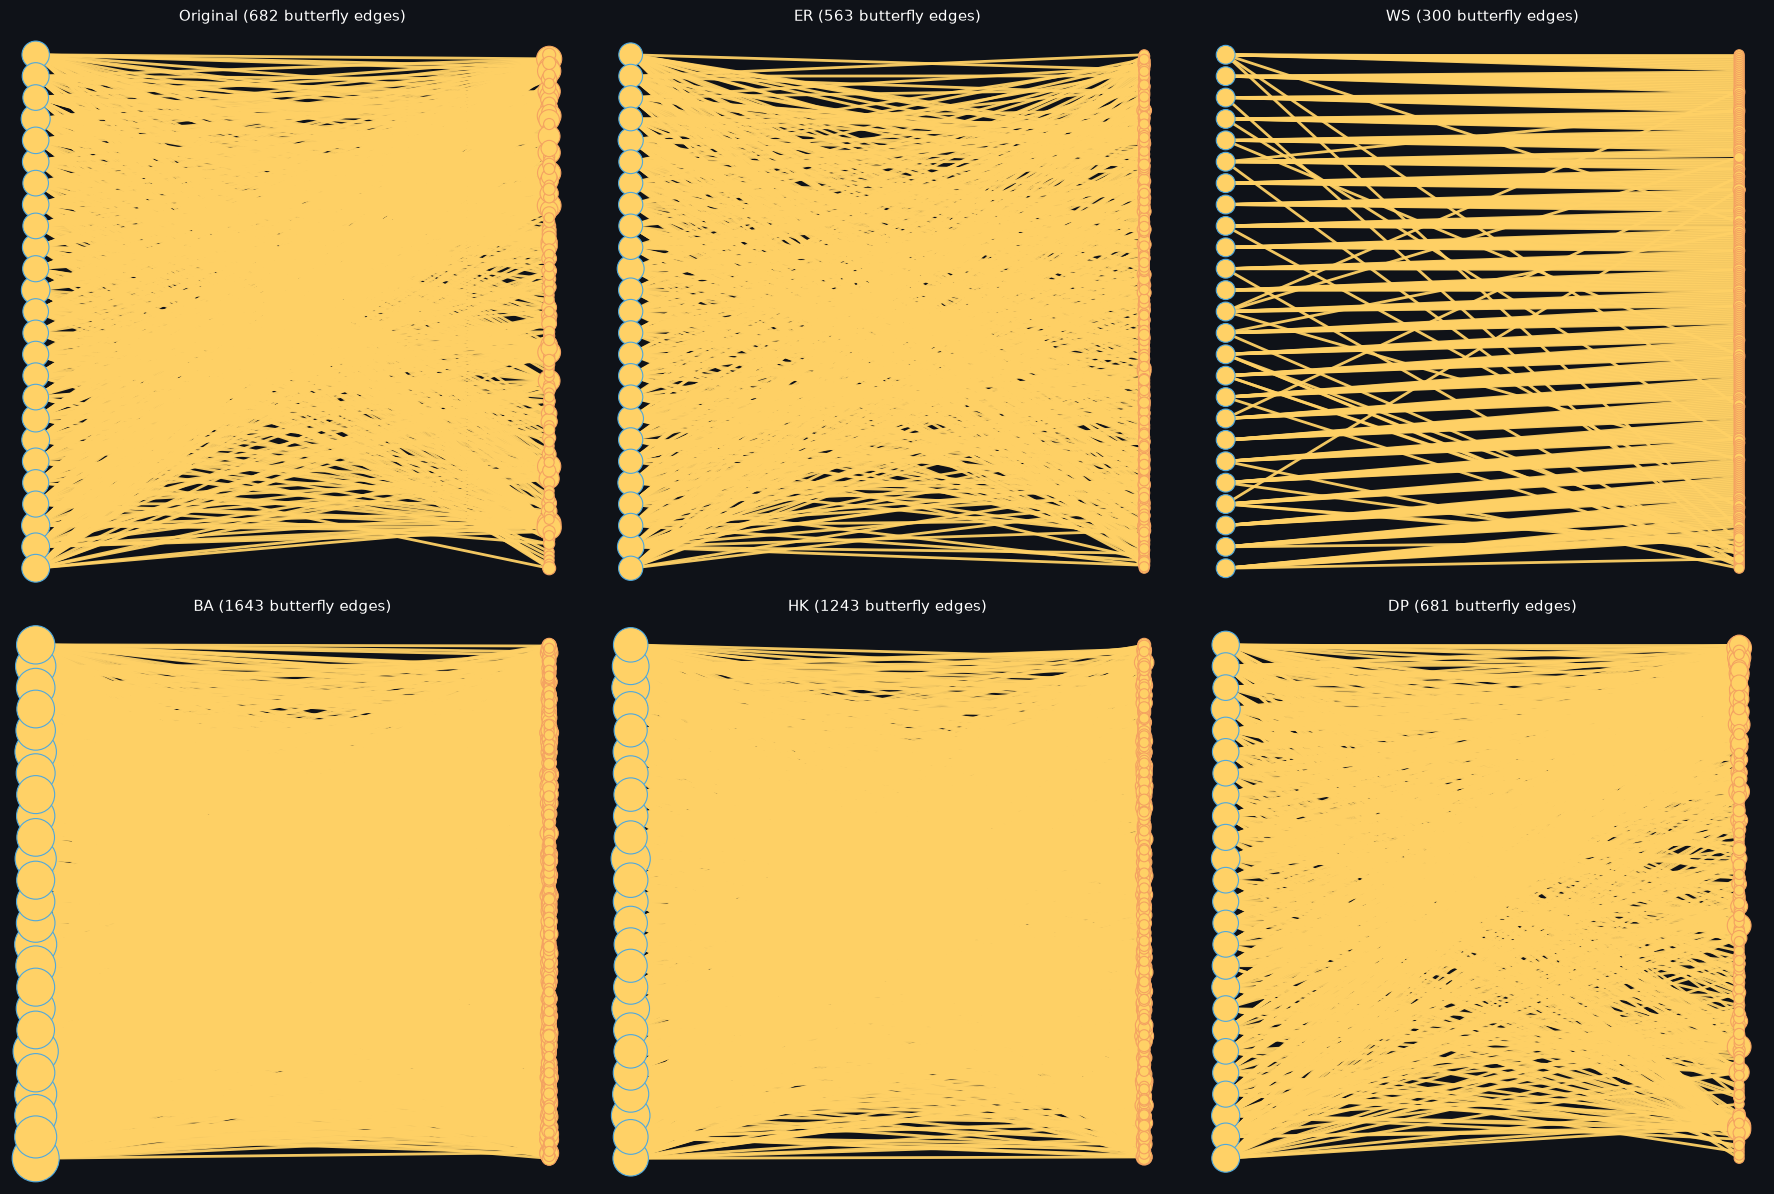

Exported Original: bipartite_outputs/Original_butterfly_coord3.gexf
Exported ER: bipartite_outputs/ER_butterfly_coord3.gexf
Exported WS: bipartite_outputs/WS_butterfly_coord3.gexf
Exported BA: bipartite_outputs/BA_butterfly_coord3.gexf
Exported HK: bipartite_outputs/HK_butterfly_coord3.gexf
Exported DP: bipartite_outputs/DP_butterfly_coord3.gexf


In [12]:
# Top 25 recipes

N_TOP_RECIPES = 25
BG, EDGE_C, HL_C = "#0f1218", "#3a4252", "#ffd166"
NODE_REC, NODE_ING = "#4ea8de", "#f4a261"

def butterfly_edge_matrix(A):
    """0/1 matrix: 1 where edge (r, c) lies on at least one 4-cycle."""
    S = A @ A.T
    np.fill_diagonal(S, 0.0)
    M = (S >= 2).astype(np.float32)                 # recipe pairs sharing >= 2 ingredients
    return A * ((M @ A) > 0)

def butterfly_view(A, top=N_TOP_RECIPES):
    hl = butterfly_edge_matrix(A)
    score = hl.sum(axis=1)
    top_r = np.argsort(-score, kind="stable")[:top]
    sub, sub_hl = A[top_r], hl[top_r]
    H = nx.Graph()
    for ri, rr in enumerate(top_r):
        for c in np.nonzero(sub[ri])[0]:
            H.add_edge(("r", int(rr)), ("i", int(c)), hl=bool(sub_hl[ri, c]))
    #pos = nx.spring_layout(H, seed=42, k=0.6)
    # starting layout
    recipe_nodes = sorted(
    [n for n in H.nodes() if n[0] == "r"],
    key=lambda n: n[1]
    )

    ingredient_nodes = sorted(
        [n for n in H.nodes() if n[0] == "i"],
        key=lambda n: n[1]
    )

    y_recipe = np.linspace(1, -1, len(recipe_nodes))
    y_ingredient = np.linspace(1, -1, len(ingredient_nodes))

    pos = {}

    for node, y in zip(recipe_nodes, y_recipe):
        pos[node] = (-1, float(y))

    for node, y in zip(ingredient_nodes, y_ingredient):
        pos[node] = (1, float(y))
    # ending layout
    return H, pos

def draw_butterfly(ax, H, pos, title):

    # Only edges that participate in butterflies
    bf = [
        (pos[u], pos[v])
        for u, v, d in H.edges(data=True)
        if d["hl"]
    ]

    # Draw butterfly edges only
    ax.add_collection(
        LineCollection(
            bf,
            colors=HL_C,
            linewidths=2.0,
            alpha=0.95
        )
    )

    # Nodes that participate in butterfly edges
    hl_nodes = {
        n
        for u, v, d in H.edges(data=True)
        if d["hl"]
        for n in (u, v)
    }

    # Draw only nodes belonging to butterfly edges
    for kind, col in (("r", NODE_REC), ("i", NODE_ING)):

        ns = [
            n for n in H.nodes
            if n[0] == kind and n in hl_nodes
        ]

        if not ns:
            continue

        xy = np.array([pos[n] for n in ns])

        sizes = [
            40 + 12 * H.degree(n)
            for n in ns
        ]

        ax.scatter(
            xy[:, 0],
            xy[:, 1],
            s=sizes,
            c=HL_C,
            edgecolors=col,
            linewidths=0.8,
            zorder=3
        )

    ax.set_facecolor(BG)
    ax.autoscale()
    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_title(
        f"{title} ({len(bf)} butterfly edges)",
        color="white",
        fontsize=11
    )

views = {"Original": butterfly_view(to_dense(rows0, cols0))}
for name in MODELS:
    views[name] = butterfly_view(to_dense(*generated[name][0]))

H0, _ = views["Original"]
print(f"Showing {H0.number_of_nodes()} nodes, {H0.number_of_edges()} edges, "
      f"{sum(d['hl'] for *_, d in H0.edges(data=True))} butterfly edges (original)")

fig, axes = plt.subplots(2, 3, figsize=(18, 12), facecolor=BG)
for ax, name in zip(axes.ravel(), MODEL_ORDER):
    draw_butterfly(ax, *views[name], name)
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "butterfly_panels.png"), dpi=150, facecolor=BG); plt.show()

# Export butterfly networks to Gephi
for name in MODEL_ORDER:

    H, pos = views[name]

    # Set node attributes and positions
    for node in H.nodes():

        x, y = pos[node]

        H.nodes[node]["type"] = (
            "Recipe" if node[0] == "r" else "Ingredient"
        )

        H.nodes[node]["viz"] = {
            "position": {
                "x": float(x),
                "y": float(y),
                "z": 0.0
            }
        }

    filepath = os.path.join(
        OUTPUT_DIR,
        f"{name}_butterfly_coord3.gexf"
    )

    nx.write_gexf(H, filepath)

    print(f"Exported {name}: {filepath}")

Showing 4501 nodes, 46669 edges, 46515 butterfly edges (original)


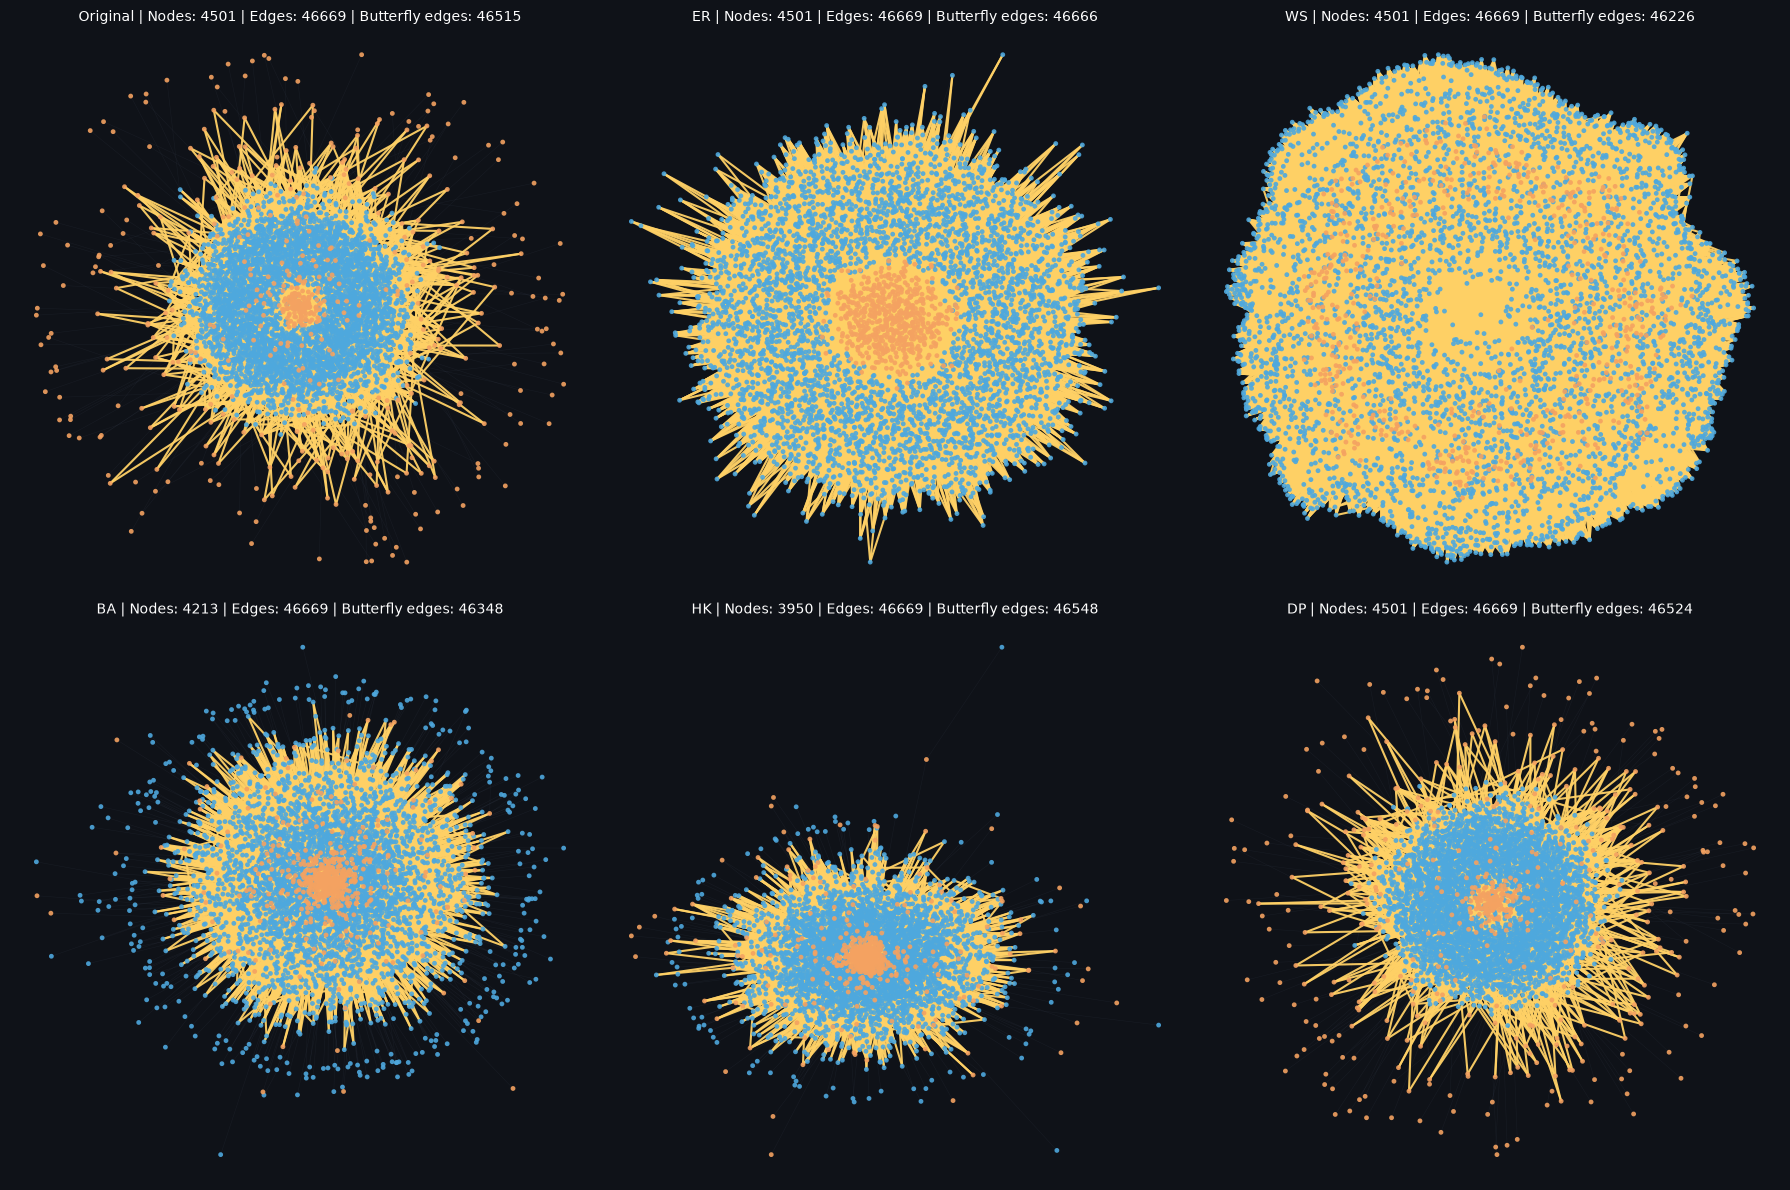

Exported Original: bipartite_outputs/Original_butterfly_allnodes.gexf
Exported ER: bipartite_outputs/ER_butterfly_allnodes.gexf
Exported WS: bipartite_outputs/WS_butterfly_allnodes.gexf
Exported BA: bipartite_outputs/BA_butterfly_allnodes.gexf
Exported HK: bipartite_outputs/HK_butterfly_allnodes.gexf
Exported DP: bipartite_outputs/DP_butterfly_allnodes.gexf


In [13]:
# all nodes

N_TOP_RECIPES = 3933
BG, EDGE_C, HL_C = "#0f1218", "#3a4252", "#ffd166"
NODE_REC, NODE_ING = "#4ea8de", "#f4a261"

def butterfly_edge_matrix(A):
    """0/1 matrix: 1 where edge (r, c) lies on at least one 4-cycle."""
    S = A @ A.T
    np.fill_diagonal(S, 0.0)
    M = (S >= 2).astype(np.float32)                 # recipe pairs sharing >= 2 ingredients
    return A * ((M @ A) > 0)

def butterfly_view(A, top=N_TOP_RECIPES):
    hl = butterfly_edge_matrix(A)
    score = hl.sum(axis=1)
    top_r = np.argsort(-score, kind="stable")[:top]
    sub, sub_hl = A[top_r], hl[top_r]
    H = nx.Graph()
    for ri, rr in enumerate(top_r):
        for c in np.nonzero(sub[ri])[0]:
            H.add_edge(("r", int(rr)), ("i", int(c)), hl=bool(sub_hl[ri, c]))
    pos = nx.spring_layout(H, seed=42, k=0.6)
    # starting layout
    return H, pos

def draw_butterfly(ax, H, pos, title):

    # All edges in the background
    all_edges = [
        (pos[u], pos[v])
        for u, v in H.edges()
    ]

    ax.add_collection(
        LineCollection(
            all_edges,
            colors=EDGE_C,
            linewidths=0.4,
            alpha=0.20,
            zorder=1
        )
    )

    # Butterfly edges highlighted
    bf = [
        (pos[u], pos[v])
        for u, v, d in H.edges(data=True)
        if d["hl"]
    ]

    ax.add_collection(
        LineCollection(
            bf,
            colors=HL_C,
            linewidths=1.5,
            alpha=0.95,
            zorder=2
        )
    )

    # Draw ALL nodes
    for kind, col in (("r", NODE_REC), ("i", NODE_ING)):

        ns = [
            n for n in H.nodes()
            if n[0] == kind
        ]

        if not ns:
            continue

        xy = np.array([pos[n] for n in ns])

        ax.scatter(
            xy[:, 0],
            xy[:, 1],
            s=12,
            c=col,
            edgecolors="none",
            alpha=0.9,
            zorder=3
        )

    ax.set_facecolor(BG)
    ax.autoscale()
    ax.set_aspect("auto")
    ax.axis("off")

    ax.set_title(
        f"{title} | Nodes: {H.number_of_nodes()} | "
        f"Edges: {H.number_of_edges()} | "
        f"Butterfly edges: {len(bf)}",
        color="white",
        fontsize=10
    )

views = {"Original": butterfly_view(to_dense(rows0, cols0))}
for name in MODELS:
    views[name] = butterfly_view(to_dense(*generated[name][0]))

H0, _ = views["Original"]
print(f"Showing {H0.number_of_nodes()} nodes, {H0.number_of_edges()} edges, "
      f"{sum(d['hl'] for *_, d in H0.edges(data=True))} butterfly edges (original)")

fig, axes = plt.subplots(2, 3, figsize=(18, 12), facecolor=BG)
for ax, name in zip(axes.ravel(), MODEL_ORDER):
    draw_butterfly(ax, *views[name], name)
fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "butterfly_panels.png"), dpi=150, facecolor=BG); plt.show()

# Export butterfly networks to Gephi
for name in MODEL_ORDER:

    H, pos = views[name]

    # Set node attributes and positions
    for node in H.nodes():

        x, y = pos[node]

        H.nodes[node]["type"] = (
            "Recipe" if node[0] == "r" else "Ingredient"
        )

        H.nodes[node]["viz"] = {
            "position": {
                "x": float(x),
                "y": float(y),
                "z": 0.0
            }
        }

    filepath = os.path.join(
        OUTPUT_DIR,
        f"{name}_butterfly_allnodes.gexf"
    )

    nx.write_gexf(H, filepath)

    print(f"Exported {name}: {filepath}")